In [1]:
!pip install -q ultralytics opencv-python matplotlib pandas numpy gradio pyyaml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.8 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU. Stop here and reconnect with GPU.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU available: False
No GPU. Stop here and reconnect with GPU.


In [5]:
from pathlib import Path
import shutil

BASE_DIR = Path("/content/drive/MyDrive/trash_detection_project")
ORIGINAL_DATASET = BASE_DIR / "working_dataset/taco_yolo"
LOCAL_DATASET = Path("/content/taco_yolo_59class")

RUNS_DIR = BASE_DIR / "runs"
OUTPUTS_DIR = BASE_DIR / "outputs"

RUNS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

if LOCAL_DATASET.exists():
    shutil.rmtree(LOCAL_DATASET)

shutil.copytree(ORIGINAL_DATASET, LOCAL_DATASET)

DATA_YAML = LOCAL_DATASET / "data_fixed.yaml"

print("Local dataset:", LOCAL_DATASET)
print("YAML exists:", DATA_YAML.exists())
print("Train images:", len(list((LOCAL_DATASET / "train/images").glob("*"))))
print("Val images:", len(list((LOCAL_DATASET / "val/images").glob("*"))))

Local dataset: /content/taco_yolo_59class
YAML exists: True
Train images: 1200
Val images: 299


In [ ]:
from ultralytics import YOLO

model_59 = YOLO("yolov8m.pt")

model_59.train(
    data=str(DATA_YAML),
    epochs=100,
    imgsz=832,
    batch=4,
    patience=25,
    pretrained=True,
    optimizer="AdamW",
    lr0=0.0006,
    lrf=0.01,
    weight_decay=0.0005,
    cos_lr=True,

  
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=8,
    translate=0.1,
    scale=0.45,
    shear=1.5,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.1,
    close_mosaic=10,

    project=str(RUNS_DIR),
    name="final_59class_yolov8m_832_best",
    save=True,
    plots=True,
    verbose=True
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/taco_yolo_59class/data_fixed.yaml, degrees=8, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hs

In [3]:
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/trash_detection_project")
RUNS_DIR = BASE_DIR / "runs"

RUN_NAME = "final_59class_yolov8m_832_best"
RUN_PATH = RUNS_DIR / RUN_NAME

BEST_PATH = RUN_PATH / "weights" / "best.pt"
LAST_PATH = RUN_PATH / "weights" / "last.pt"

print("Run folder exists:", RUN_PATH.exists())
print("best.pt exists:", BEST_PATH.exists())
print("last.pt exists:", LAST_PATH.exists())

print("\nRun folder:", RUN_PATH)

if RUN_PATH.exists():
    print("\nFiles:")
    for p in RUN_PATH.glob("*"):
        print(p.name)

Run folder exists: True
best.pt exists: True
last.pt exists: True

Run folder: /content/drive/MyDrive/trash_detection_project/runs/final_59class_yolov8m_832_best

Files:
weights
args.yaml
labels.jpg
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
results.csv


In [7]:
from ultralytics import YOLO

model_final = YOLO(str(BEST_PATH))

metrics = model_final.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=832,
    conf=0.001,
    iou=0.6,
    plots=True
)

p_final = float(metrics.box.mp)
r_final = float(metrics.box.mr)
map50_final = float(metrics.box.map50)
map5095_final = float(metrics.box.map)

# F1 score
f1_final = 2 * (p_final * r_final) / (p_final + r_final + 1e-9)

print("Final YOLOv8m Best Model Results")
print("Precision:", p_final)
print("Recall:", r_final)
print("F1 Score:", f1_final)
print("mAP@50:", map50_final)
print("mAP@50-95:", map5095_final)

Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 93 layers, 25,873,921 parameters, 0 gradients, 78.9 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 10.6±21.2 ms, read: 92.2±63.2 MB/s, size: 1252.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips/
val: Scanning /content/drive/.shortcut-targets-by-id/1MZmkUCzyE34Xtq8v4CuerxH38fUzrXG8/trash_detection_project/working_dataset/taco_yolo/val/labels.cache... 299 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 299/299 44.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 45.8s/it 14:31
                   all        299        962      0.413      0.194      0.183      0.158
               Aerosol          4          4      0.634      0.451      0.574      0.549
Aluminium blister pack          2          2      

In [ ]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/trash_detection_project")
RUN_PATH = BASE_DIR / "runs/final_59class_yolov8m_832_best"

results_csv = RUN_PATH / "results.csv"

print("results.csv exists:", results_csv.exists())

df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()

print(df.columns.tolist())
best_precision_row = df.loc[df["metrics/precision(B)"].idxmax()]

best_precision_epoch = int(best_precision_row["epoch"])
best_precision = best_precision_row["metrics/precision(B)"]
best_precision_recall = best_precision_row["metrics/recall(B)"]
best_precision_map50 = best_precision_row["metrics/mAP50(B)"]
best_precision_map5095 = best_precision_row["metrics/mAP50-95(B)"]

peak_precision_table = pd.DataFrame([
    {
        "Model": "YOLOv8m Final",
        "Selection Method": "Highest Precision Epoch",
        "Epoch": best_precision_epoch,
        "Precision": round(best_precision, 4),
        "Recall": round(best_precision_recall, 4),
        "mAP@50": round(best_precision_map50, 4),
        "mAP@50-95": round(best_precision_map5095, 4)
    }
])

peak_precision_table

results.csv exists: True
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


,Model,Selection Method,Epoch,Precision,Recall,mAP@50,mAP@50-95
0,YOLOv8m Final,Highest Precision Epoch,46,0.5966,0.165,0.161,0.1394


In [11]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/trash_detection_project")
OUTPUTS_DIR = BASE_DIR / "outputs"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

comparison = pd.DataFrame([
    {
        "Model": "YOLOv8n Baseline",
        "Epochs": 30,
        "Image Size": 640,
        "Precision": 0.480,
        "Recall": 0.170,
        "F1 Score": round(2*(0.480*0.170)/(0.480+0.170), 4),
        "mAP@50": 0.140,
        "mAP@50-95": 0.110,
        "Notes": "Baseline model"
    },
    {
        "Model": "YOLOv8s Improved",
        "Epochs": 57,
        "Image Size": 960,
        "Precision": 0.394,
        "Recall": 0.224,
        "F1 Score": round(2*(0.394*0.224)/(0.394+0.224), 4),
        "mAP@50": 0.181,
        "mAP@50-95": 0.145,
        "Notes": "Higher resolution + augmentation"
    },
    {
        "Model": "YOLOv8m Final",
        "Epochs": 86,
        "Image Size": 832,
        "Precision": 0.413,
        "Recall": 0.194,
        "F1 Score": 0.264,
        "mAP@50": 0.183,
        "mAP@50-95": 0.158,
        "Notes": "Stronger model + best.pt checkpoint"
    }
])

comparison_path = OUTPUTS_DIR / "final_model_comparison.csv"
comparison.to_csv(comparison_path, index=False)

comparison

,Model,Epochs,Image Size,Precision,Recall,F1 Score,mAP@50,mAP@50-95,Notes
0,YOLOv8n Baseline,30,640,0.480,0.170,0.2511,0.140,0.110,Baseline model
1,YOLOv8s Improved,57,960,0.394,0.224,0.2856,0.181,0.145,Higher resolution + augmentation
2,YOLOv8m Final,86,832,0.413,0.194,0.2640,0.183,0.158,Stronger model + best.pt checkpoint


In [12]:
import shutil
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/trash_detection_project")
RUN_PATH = BASE_DIR / "runs/final_59class_yolov8m_832_best"
OUTPUTS_DIR = BASE_DIR / "outputs"
PPT_IMAGES_DIR = OUTPUTS_DIR / "presentation_images"

PPT_IMAGES_DIR.mkdir(parents=True, exist_ok=True)

important_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "val_batch0_pred.jpg",
    "val_batch1_pred.jpg",
    "val_batch2_pred.jpg",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png"
]

for file_name in important_files:
    src = RUN_PATH / file_name
    dst = PPT_IMAGES_DIR / file_name

    if src.exists():
        shutil.copy(src, dst)
        print("Copied:", file_name)
    else:
        print("Missing:", file_name)

print("Presentation images saved to:", PPT_IMAGES_DIR)

Missing: results.png
Missing: confusion_matrix.png
Missing: confusion_matrix_normalized.png
Missing: val_batch0_pred.jpg
Missing: val_batch1_pred.jpg
Missing: val_batch2_pred.jpg
Missing: BoxPR_curve.png
Missing: BoxF1_curve.png
Missing: BoxP_curve.png
Missing: BoxR_curve.png
Presentation images saved to: /content/drive/MyDrive/trash_detection_project/outputs/presentation_images


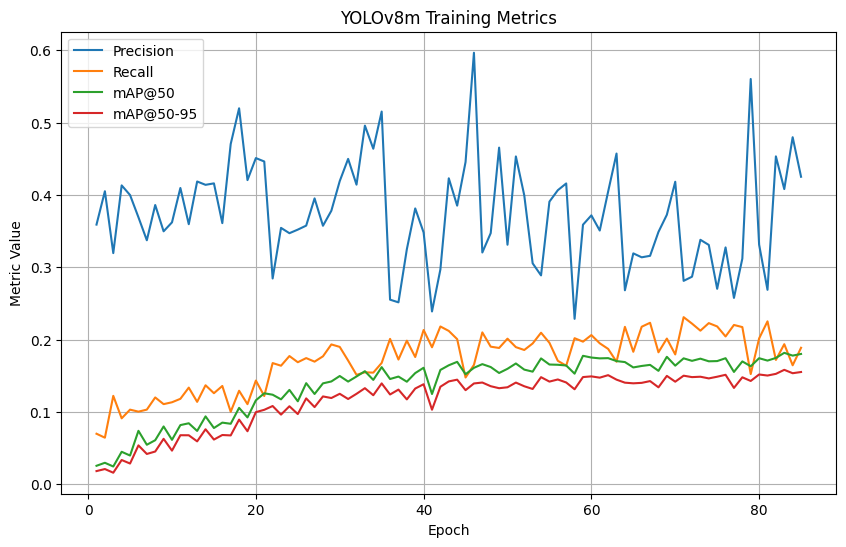

Saved: /content/drive/MyDrive/trash_detection_project/outputs/presentation_images/custom_training_metrics.png


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/trash_detection_project")
RUN_PATH = BASE_DIR / "runs/final_59class_yolov8m_832_best"
results_csv = RUN_PATH / "results.csv"

df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()

plt.figure(figsize=(10, 6))
plt.plot(df["epoch"], df["metrics/precision(B)"], label="Precision")
plt.plot(df["epoch"], df["metrics/recall(B)"], label="Recall")
plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP@50")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP@50-95")
plt.xlabel("Epoch")
plt.ylabel("Metric Value")
plt.title("YOLOv8m Training Metrics")
plt.legend()
plt.grid(True)

save_path = BASE_DIR / "outputs/presentation_images/custom_training_metrics.png"
plt.savefig(save_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", save_path)

In [13]:
!pip install -q ultralytics opencv-python matplotlib numpy pandas

Results saved to /content/drive/.shortcut-targets-by-id/1MZmkUCzyE34Xtq8v4CuerxH38fUzrXG8/trash_detection_project/outputs/final_single_prediction


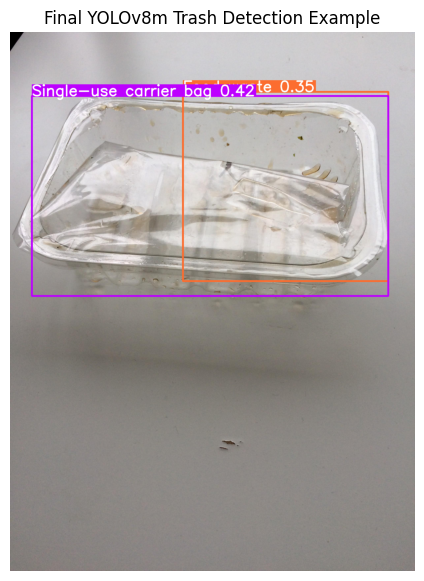

Test image: /content/drive/MyDrive/trash_detection_project/working_dataset/taco_yolo/val/images/IMG_4876_JPG.rf.b8d0a37b9a6015542e7aa89d977abea4.jpg


In [14]:
from ultralytics import YOLO
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import random

BASE_DIR = Path("/content/drive/MyDrive/trash_detection_project")
RUN_PATH = BASE_DIR / "runs/final_59class_yolov8m_832_best"
BEST_PATH = RUN_PATH / "weights/best.pt"

DATA_YAML = BASE_DIR / "working_dataset/taco_yolo/data_fixed.yaml"
val_images_dir = DATA_YAML.parent / "val" / "images"

model_final = YOLO(str(BEST_PATH))

val_images = list(val_images_dir.glob("*"))
random.seed(42)
test_image = random.choice(val_images)

results = model_final.predict(
    source=str(test_image),
    imgsz=832,
    conf=0.25,
    iou=0.5,
    save=True,
    project=str(BASE_DIR / "outputs"),
    name="final_single_prediction",
    verbose=False
)

result = results[0]
plotted = result.plot()
plotted = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(plotted)
plt.title("Final YOLOv8m Trash Detection Example")
plt.axis("off")
plt.show()

print("Test image:", test_image)

In [15]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

def create_trash_heatmap(image, boxes, confidences):
    h, w = image.shape[:2]
    heatmap = np.zeros((h, w), dtype=np.float32)

    for box, conf in zip(boxes, confidences):
        x1, y1, x2, y2 = map(int, box)

        x1 = max(0, min(x1, w - 1))
        x2 = max(0, min(x2, w - 1))
        y1 = max(0, min(y1, h - 1))
        y2 = max(0, min(y2, h - 1))

        if x2 <= x1 or y2 <= y1:
            continue

        heatmap[y1:y2, x1:x2] += float(conf)

    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    heatmap_uint8 = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)

    overlay = cv2.addWeighted(image, 0.65, heatmap_color, 0.35, 0)

    return heatmap_color, overlay


def calculate_cleanliness_score(image, boxes, confidences):
    h, w = image.shape[:2]
    image_area = h * w

    if len(boxes) == 0:
        return 100.0

    pollution_score = 0

    for box, conf in zip(boxes, confidences):
        x1, y1, x2, y2 = box
        box_area = max(0, x2 - x1) * max(0, y2 - y1)
        area_ratio = box_area / image_area

        pollution_score += area_ratio * float(conf) * 1000

    pollution_score += len(boxes) * 3

    cleanliness = 100 - pollution_score
    cleanliness = max(0, min(100, cleanliness))

    return round(cleanliness, 2)


def get_cleanliness_label(score):
    if score >= 80:
        return "Clean"
    elif score >= 50:
        return "Moderately littered"
    elif score >= 25:
        return "Polluted"
    else:
        return "Highly polluted"

Image: IMG_4876_JPG.rf.b8d0a37b9a6015542e7aa89d977abea4.jpg
Detected trash objects: 2
Detected classes: ['Single-use carrier bag', 'Food waste']
Cleanliness score: 0
Cleanliness label: Highly polluted


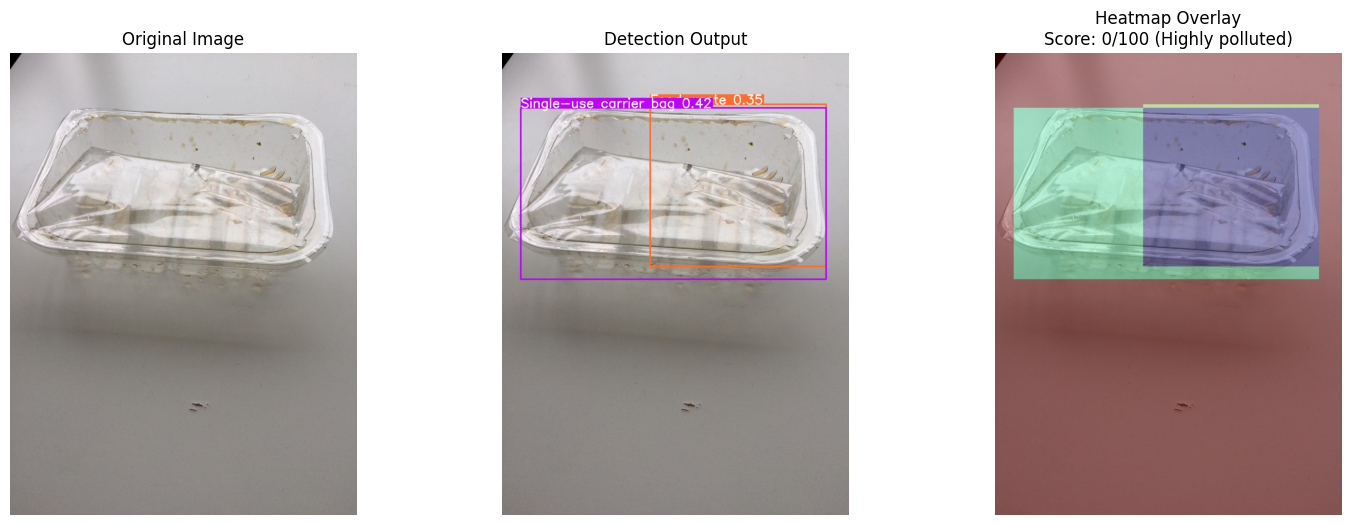

{'image': 'IMG_4876_JPG.rf.b8d0a37b9a6015542e7aa89d977abea4.jpg',
 'detections': 2,
 'classes': ['Single-use carrier bag', 'Food waste'],
 'cleanliness_score': 0,
 'cleanliness_label': 'Highly polluted'}

In [16]:
def analyze_single_image(image_path, model, conf=0.25):
    image_path = Path(image_path)

    results = model.predict(
        source=str(image_path),
        imgsz=832,
        conf=conf,
        iou=0.5,
        verbose=False
    )

    result = results[0]

    image = cv2.imread(str(image_path))
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    boxes = []
    confidences = []
    class_names = []

    if result.boxes is not None:
        for box in result.boxes:
            xyxy = box.xyxy[0].cpu().numpy()
            conf_score = float(box.conf[0].cpu().numpy())
            cls_id = int(box.cls[0].cpu().numpy())

            boxes.append(xyxy)
            confidences.append(conf_score)
            class_names.append(model.names[cls_id])

    heatmap, overlay = create_trash_heatmap(image_rgb, boxes, confidences)
    cleanliness_score = calculate_cleanliness_score(image_rgb, boxes, confidences)
    cleanliness_label = get_cleanliness_label(cleanliness_score)

    print("Image:", image_path.name)
    print("Detected trash objects:", len(boxes))
    print("Detected classes:", class_names)
    print("Cleanliness score:", cleanliness_score)
    print("Cleanliness label:", cleanliness_label)

    plotted = result.plot()
    plotted = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(18, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(image_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(plotted)
    plt.title("Detection Output")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title(f"Heatmap Overlay\nScore: {cleanliness_score}/100 ({cleanliness_label})")
    plt.axis("off")

    plt.show()

    return {
        "image": image_path.name,
        "detections": len(boxes),
        "classes": class_names,
        "cleanliness_score": cleanliness_score,
        "cleanliness_label": cleanliness_label
    }


analysis_result = analyze_single_image(test_image, model_final, conf=0.25)
analysis_result

In [17]:
!pip install -q gradio

In [18]:
import gradio as gr
from PIL import Image
import pandas as pd
import numpy as np
import cv2

APP_DIR = BASE_DIR / "app_outputs"
APP_DIR.mkdir(parents=True, exist_ok=True)

def trash_detection_assistant(input_image):
    if input_image is None:
        return None, None, "Please upload an image."

    image_rgb = np.array(input_image)

    temp_path = APP_DIR / "uploaded_image.jpg"
    cv2.imwrite(str(temp_path), cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR))

    results = model_final.predict(
        source=str(temp_path),
        imgsz=832,
        conf=0.25,
        iou=0.5,
        verbose=False
    )

    result = results[0]

    boxes = []
    confidences = []
    detected_classes = []

    if result.boxes is not None:
        for box in result.boxes:
            xyxy = box.xyxy[0].cpu().numpy()
            conf_score = float(box.conf[0].cpu().numpy())
            cls_id = int(box.cls[0].cpu().numpy())

            boxes.append(xyxy)
            confidences.append(conf_score)
            detected_classes.append(model_final.names[cls_id])

    detection_img = result.plot()
    detection_img = cv2.cvtColor(detection_img, cv2.COLOR_BGR2RGB)

    heatmap, overlay = create_trash_heatmap(image_rgb, boxes, confidences)

    cleanliness_score = calculate_cleanliness_score(image_rgb, boxes, confidences)
    cleanliness_label = get_cleanliness_label(cleanliness_score)

    summary = "Assistant Summary:\n"
    summary += f"Detected trash objects: {len(boxes)}\n"
    summary += f"Cleanliness Score: {cleanliness_score}/100\n"
    summary += f"Cleanliness Level: {cleanliness_label}\n\n"

    if len(detected_classes) == 0:
        summary += "No trash objects were detected. The area appears clean based on the model prediction."
    else:
        class_counts = pd.Series(detected_classes).value_counts().to_dict()

        summary += "Detected object types:\n"
        for cls, count in class_counts.items():
            summary += f"- {cls}: {count}\n"

        summary += "\nInterpretation:\n"
        summary += (
            "The system detected visible litter in the image. "
            "The heatmap highlights areas with higher trash concentration. "
            "The cleanliness score is calculated using object count, object size, and confidence."
        )

    return detection_img, overlay, summary


demo = gr.Interface(
    fn=trash_detection_assistant,
    inputs=gr.Image(type="pil", label="Upload trash/litter image"),
    outputs=[
        gr.Image(type="numpy", label="Detection Output"),
        gr.Image(type="numpy", label="Heatmap Overlay"),
        gr.Textbox(label="Assistant Summary", lines=14)
    ],
    title="Trash Detection and Cleanliness Assistant",
    description=(
        "Upload an image to detect trash objects, visualize litter hotspots, "
        "calculate a cleanliness score, and receive an assistant-style summary."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://92f4dd53b040269b03.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
